In [72]:
# compare various iterations of LSE calibration

import sys, os, glob, pickle, toml, json
import pickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.cm as cm
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xarray as xr


def get_iter_num(inpath):
    folders=glob.glob(f'{inpath}/*/')
    folders.sort()
    folder = folders[0]
    for i in range(1, 100):
        if not os.path.isfile(f'{folder}/outputs/iter{i}_all_metric.csv'):
            return i-1

In [73]:
tarexp = 'exp11'

In [74]:
outpath_parent = f"/glade/campaign/cgd/tss/people/guoqiang/HBV_CAMELS/LSE{tarexp}"
config_file = f'config_LSE{tarexp}.toml'
config = toml.load(config_file)
outpath_external_iter0 = ""
if 'external_iter0' in config['output']:
    external_iter0 = config['output']['external_iter0']
    if external_iter0 == True:
        outpath_external_iter0 = config['output']['external_iter0_path']

iternum = get_iter_num(outpath_parent)

subsetPath = f'/glade/campaign/cgd/tss/people/guoqiang/HBV_CAMELS/data_Yalan/Sub531ID.txt'
with open(subsetPath, 'r') as fp:
     camels_ids = json.load(fp)

print('Iteration number:', iternum)

Iteration number: 10


In [75]:
# LSE metrics

df_lse_metric = []
for tarbasin in range(len(camels_ids)):
    idi = camels_ids[tarbasin]
    for i in range(iternum):
        if i == 0 and len(outpath_external_iter0)>0:
            infile = f'{outpath_external_iter0}/{idi}/outputs/iter{i}_all_metric.csv'    
        else:
            infile = f'{outpath_parent}/{idi}/outputs/iter{i}_all_metric.csv'   

        if os.path.isfile(infile):
            dfi = pd.read_csv(infile)
            dfi['basin'] = tarbasin
            dfi['iter'] = i
            dfi['trial'] = np.arange(len(dfi))
            if len(df_lse_metric) == 0:
                df_lse_metric = dfi
            else:
                df_lse_metric = pd.concat([df_lse_metric, dfi])
        else:
            # print('File not exist:', infile)
            pass

Best of each iteration for nse
[0.50457261 0.65068978 0.69517423 0.71481359 0.72924283 0.73752218
 0.7411229  0.7444019  0.74623238 0.74743112]
Best of each iteration for kge2009
[0.63714877 0.74963796 0.78576764 0.80484236 0.81232741 0.82092626
 0.82765441 0.83214972 0.83433949 0.83494907]


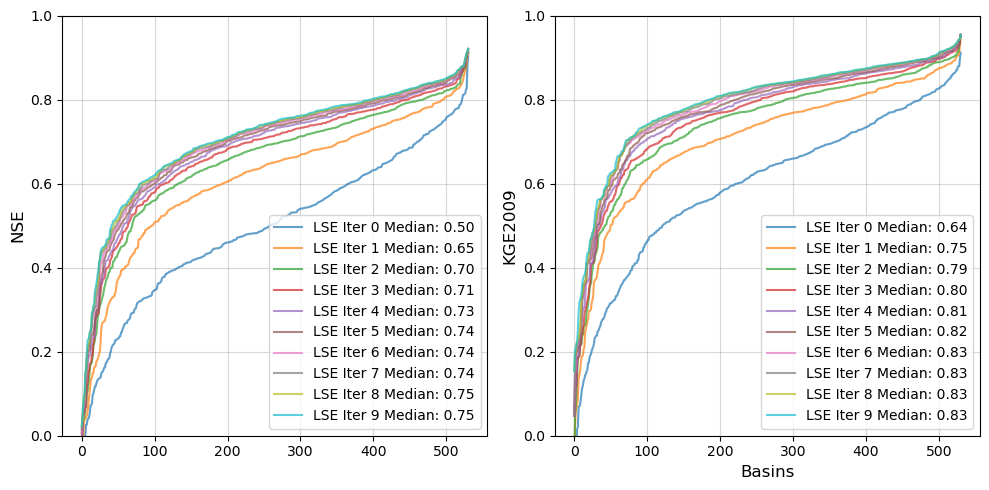

In [76]:
# best of all iterations <= i

metrics = ['nse', 'kge2009']
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True)

for idx, metname in enumerate(metrics):
    met_stats_lse = np.nan * np.zeros([len(camels_ids), iternum, 3])  # best; mean; median

    # Calculate metrics statistics
    for i in range(iternum):
        indi = (df_lse_metric['iter'] <= i) # best of all iterations <= i
        for j in range(len(camels_ids)):
            indij = indi & (df_lse_metric['basin'] == j)
            dij = df_lse_metric[indij][metname].values

            if len(dij)>0:
                met_stats_lse[j, i, 0] = np.nanmax(dij)
                met_stats_lse[j, i, 1] = np.nanmean(dij)
                met_stats_lse[j, i, 2] = np.nanmedian(dij)

    print(f'Best of each iteration for {metname}')
    print(np.nanmedian(met_stats_lse[:, :, 0], axis=0))

    # Calculate median values
    median_met_stats_lse = [np.nanmedian(met_stats_lse[:, i, 0]) for i in range(iternum)]

    # Plot each metric
    for i in range(iternum):
        axes[idx].plot(np.sort(met_stats_lse[:, i, 0]),
                       label=f'LSE Iter {i} Median: {median_met_stats_lse[i]:.2f}', alpha=0.7)

    # Enhance aesthetics for the subplot
    axes[idx].set_ylabel(metname.upper(), fontsize=12)
    axes[idx].legend(loc='best', fontsize=10)
    axes[idx].grid(alpha=0.5)
    axes[idx].set_ylim(0, 1)

# Shared xlabel
axes[-1].set_xlabel("Basins", fontsize=12)

# Tight layout and save the figure
plt.tight_layout()
plt.savefig(f"LSE{tarexp}_nse_kge_CDF.png", dpi=300)
plt.show()
